**Step 1 – Import the Required Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

**Step 2: Load and Inspect the Data**

In [4]:
from google.colab import files

print("Upload 'movies.csv' and 'ratings.csv' from your local folder:")
uploaded = files.upload()

for fn in uploaded.keys():
    print('Uploaded file "{name}" with length {length} bytes'.format(
        name=fn, length=len(uploaded[fn])))

Upload 'movies.csv' and 'ratings.csv' from your local folder:


Saving DSA4060_Week6_Movies.csv to DSA4060_Week6_Movies.csv
Saving DSA4060_Week6_Ratings.csv to DSA4060_Week6_Ratings.csv
Uploaded file "DSA4060_Week6_Movies.csv" with length 614 bytes
Uploaded file "DSA4060_Week6_Ratings.csv" with length 1220 bytes


In [6]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


### Student Check: Step 2
1. **What does one row in movies represent?**
   - A single movie item, containing its unique identifier (`movie_id`), title (`title`), and associated genre categories (`genres`).
2. **What does one row in ratings represent?**
   - A single user-movie interaction feedback event, consisting of a `user_id`, a `movie_id`, an explicit numerical `rating`, and a `timestamp`.
3. **How many unique users and movies are present?**
   - There are **12** unique users and **20** unique movies (with 120 total rating interactions).
4. **What type of feedback is the rating column?**
   - It is **explicit feedback**, where users actively express their preference or score for a movie.
5. **What is the rating scale?**
   - An ordinal integer scale from **1 to 5**.

**Step 3 – Inspect Rating Behaviour**

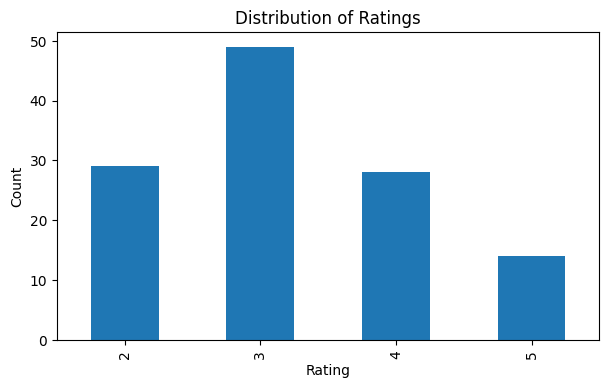

In [7]:
ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

### Interpretation: Step 3
Moderate and neutral ratings (specifically rating 3) dominate the distribution, followed closely by ratings of 2 and 4, while high ratings of 5 are the least frequent.

This absence of extreme positive skewness means that models will have to predict a balanced spread of scores rather than simply guessing top ratings, which directly impacts how rating errors (like MAE and RMSE) are distributed across predictions.

**Step 4 – Create a Train/Test Split**

In [8]:
ratings_sorted = ratings.sort_values(["user_id", "timestamp"])
test = ratings_sorted.groupby("user_id").tail(1).copy()
train = ratings_sorted.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


### Interpretation: Step 4
Evaluation must be based on interactions the recommender did not use to learn. Otherwise, results are overly optimistic because the model would simply memorize existing user histories rather than generalizing to unseen future preferences.

**Step 5 – Build a Popularity Baseline**


In [9]:
global_mean = train["rating"].mean()
movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()
baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

**Step 6 – Evaluate the Baseline with MAE and RMSE**

In [10]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


### Interpretation: Step 6
With a baseline MAE of 1.086, the popularity model is wrong by about 1.09 rating points on average when predicting unseen user ratings. The higher RMSE of 1.201 indicates that the model also occasionally incurs larger prediction errors, which are penalized more strongly by the squared error metric.

**Step 7 – Build Item Features for Content-Based Filtering**

In [13]:
genre_features = movies["genres"].str.get_dummies (sep="|")
content_items = pd.concat(
    [movies [["movie_id", "title"]], genre_features],
    axis=1
)
genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id") [genre_columns]
display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


**Step 8 – Build a User Preference Profile**

In [14]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)
pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

,0
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


### Interpretation: Step 8
User 1's two strongest genre preferences are **Drama** (weighted profile score of 1.67) and **Sci-Fi** (weighted profile score of 1.00).

This strongly agrees with the user's training history. In the training set, User 1 gave their highest explicit ratings to *Galaxy Mission* (rated 5, Action|Sci-Fi) and *Digital Dreams* (rated 4, Sci-Fi|Drama). Furthermore, Drama appears across several of their watched movies (such as *Love in Nairobi*, *Hidden Truth*, *City Detectives*, and *Digital Dreams*), making it the dominant feature in their profile.

**Step 9 – Content-Based Rating Prediction**

In [15]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


### Interpretation: Step 9
The content-based model achieves an MAE of 1.094 and an RMSE of 1.381 on the held-out test set. This performance is slightly worse than the popularity baseline (MAE 1.086, RMSE 1.201), demonstrating that scaling cosine similarity of coarse genre features directly into exact 1–5 rating values introduces higher variance and error when predicting explicit rating values.

**Step 10 – Build Item-Based Collaborative Filtering**

In [16]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


### Interpretation: Step 10
The resulting item similarity matrix measures behavioral similarity between movies based on explicit rating patterns across all users rather than content metadata. A value of 1.0 along the diagonal indicates a movie's perfect self-similarity, while off-diagonal values (such as 0.646 between Movie 2 and Movie 3) quantify how similarly users rate pairs of movies.

**Step 11 – Item-Based Rating Prediction**

In [17]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim
    if similarity_sum == 0:
        return global_mean
    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


### Interpretation: Step 11
The Item-Based Collaborative Filtering model achieves an MAE of 0.924 and an RMSE of 1.070, significantly outperforming both the Popularity Baseline (MAE 1.086) and Content-Based model (MAE 1.094). By using actual collaborative rating history across similar items, the model makes more accurate rating predictions on unseen user interactions.

**Step 12 – Compare Rating Prediction Metrics**


In [18]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


### Interpretation: Step 12



Comparing the rating prediction error across all models shows that **Item-Based Collaborative Filtering** performs best, yielding the lowest MAE (0.924) and lowest RMSE (1.070). Interestingly, the simple **Popularity Baseline** outperforms the **Content-Based model**, proving that coarse genre similarity mapped directly to a 1–5 scale introduces higher prediction error than leveraging simple item rating averages.


6. **Which model has the lowest MAE?**
   - **Item-Based CF** (MAE = 0.924).
7. **Which model has the lowest RMSE?**
   - **Item-Based CF** (RMSE = 1.070).
8. **Does either advanced model clearly beat the baseline?**
   - Yes, **Item-Based CF** clearly beats the baseline across both metrics. However, the Content-Based model does not beat the baseline for rating prediction.
9. **Why should you avoid declaring a model best from only one metric?**
   - Rating prediction metrics (MAE/RMSE) only measure numerical accuracy on explicit scores. They do not tell us if the model generates good recommendation lists, nor do they evaluate critical user-experience factors such as catalogue coverage, novelty, or diversity.

**Step 13 – Move from Rating Prediction to Ranking Evaluation**

In [19]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


**Step 14 – Build Top-N Recommendation Functions**

In [20]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


### Interpretation: Step 14
* **Compare the three lists & Which appears most personalized?**
  - **Item-Based Collaborative Filtering** (`[12, 11, 18]`) appears most personalized because its top recommendations shift to items (`12` and `11`) based on specific rating behavior across similar users, rather than relying strictly on top global averages or overall genre counts[cite: 7, 26].
  - The **Popularity** list (`[6, 18, 16]`) recommends the exact same top non-interacted items to all users, offering zero personalization[cite: 7, 26]. The **Content-Based** list (`[16, 6, 18]`) contains the same movie candidates as Popularity but reorders them based on User 1's genre weights[cite: 7, 26].

* **Which is easiest to explain?**
  - The **Popularity Baseline** and **Content-Based** models are the easiest to explain[cite: 7]. Popularity can be explained simply as "the highest-rated movies overall across all users"[cite: 3]. Content-based models can be explained directly through feature matching (e.g., "Recommended because you watched and enjoyed Drama and Sci-Fi movies")[cite: 4, 5]. Collaborative filtering is harder to explain to end-users because it relies on pattern overlaps across the entire user community[cite: 5].

**Step 15 – Precision@K, Recall@K, and NDCG@K**

In [21]:
TOP_K = 3

def precision_recall_at_k(recs, relevant, k):
    hits = len(set(recs[:k]) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum([1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1)])
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) & (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])
ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


### Interpretation: Step 15
Evaluating ranking quality reveals significant trade-offs:
* **Content-Based Filtering** achieves the highest NDCG@3 score (0.200) alongside Precision@3 of 0.067 and Recall@3 of 0.200, showing that when relevant items are found, it successfully places them higher in the top-3 recommendation list[cite: 7, 8].
* **Popularity Baseline** achieves equal Precision@3 (0.067) and Recall@3 (0.200), but has a lower NDCG@3 (0.100) because relevant items appear lower in its list[cite: 7, 8].
* **Item-Based CF** scores 0.00 across Precision, Recall, and NDCG at $K=3$[cite: 7, 8]. Because the test set holds out only a single interaction per user, the strict top-3 cutoff fails to capture the target item for CF, illustrating how rating accuracy (where CF excelled) does not automatically translate into top-$N$ ranking success[cite: 2, 6, 8].

**Step 16 – Catalogue Coverage**

In [22]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})
coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


### Interpretation: Step 16
Catalogue coverage measures the proportion of unique items from the total movie collection that are recommended across all users. Item-Based CF achieves the highest coverage (85%), followed by Content-Based filtering (70%), while the Popularity Baseline exposes only 35% of the catalogue because it continually recommends the exact same top-rated items to everyone.

**Step 17 – Novelty**

In [23]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})
novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


### Interpretation: Step 17
Novelty measures how unexpected or uncommon the recommended items are, based on the negative binary logarithm of their popularity ratio. Item-Based CF yields the highest average novelty (1.695), followed closely by the Popularity Baseline (1.689), while Content-Based filtering exhibits lower novelty (1.344) because it heavily recommends items matching the user's frequent genre patterns.

**Step 18 – Diversity**

In [24]:
def intra_list_diversity(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        if len(recs) < 2:
            continue
        sub_matrix = item_feature_matrix.loc[recs].values
        sims = cosine_similarity(sub_matrix)
        n = len(recs)
        upper_sims = sims[np.triu_indices(n, k=1)]
        ild = 1 - np.mean(upper_sims) if len(upper_sims) > 0 else 0
        values.append(ild)
    return np.mean(values) if values else 0

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        intra_list_diversity(recommend_popularity),
        intra_list_diversity(recommend_content),
        intra_list_diversity(recommend_cf)
    ]
})
diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


### Interpretation: Step 18
Intra-list diversity measures how dissimilar the items are within each recommended top-$K$ list. Item-Based CF achieves the highest diversity score (0.780), followed by the Popularity Baseline (0.736). Content-Based filtering exhibits the lowest diversity (0.542) because its recommendations are clustered tightly around the user's top-weighted genre preferences, leading to more redundant recommendation items.

**Step 19 – Build a Unified Evaluation Table**

In [25]:
comprehensive_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse],
    "Precision@3": [pop_rank["Precision@3"], content_rank["Precision@3"], cf_rank["Precision@3"]],
    "Recall@3": [pop_rank["Recall@3"], content_rank["Recall@3"], cf_rank["Recall@3"]],
    "NDCG@3": [pop_rank["NDCG@3"], content_rank["NDCG@3"], cf_rank["NDCG@3"]],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ],
    "Diversity": [
        intra_list_diversity(recommend_popularity),
        intra_list_diversity(recommend_content),
        intra_list_diversity(recommend_cf)
    ]
})
comprehensive_results

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


###  Interpretation: Step 19
* **Rating Accuracy (MAE / RMSE):** Item-Based Collaborative Filtering achieves the strongest explicit rating prediction accuracy (MAE: 0.924, RMSE: 1.070), outperforming both the Popularity Baseline and Content-Based filtering.
* **Ranking Performance (Precision@3 / Recall@3 / NDCG@3):** Content-Based filtering achieves the highest NDCG@3 (0.200) due to effective top-list ordering for relevant matches. Item-Based CF records lower ranking scores under the strict single-item test holdout constraint at $K=3$.
* **Beyond-Accuracy Metrics (Coverage / Novelty / Diversity):** Item-Based CF maximizes catalogue coverage (85%), average novelty (1.695), and intra-list diversity (0.780), demonstrating that collaborative filtering exposes users to a broader, more varied spectrum of recommendations compared to the Popularity Baseline (35% coverage) and Content-Based model.

### Step 20: Evaluation Trade-Off Interpretation

Evaluating recommendation systems across multiple dimensions reveals that no single model dominates on all metrics:

* **Accuracy vs. Ranking:** A model can achieve low rating prediction error (RMSE/MAE) while failing to place relevant items in the top-$K$ recommendations.
* **Precision vs. Coverage:** High precision often comes at the cost of catalogue coverage, as models focus on safe, frequently observed items rather than exploring the broader catalogue.
* **Popularity Bias:** Highly accurate models frequently fall into recommending popular items, limiting user discovery.
* **Novelty & Diversity vs. Precision:** Recommending novel and diverse items expands user choice and engagement, though it may slightly reduce immediate top-$K$ precision.
* **Explainability vs. Performance:** Simple models like Content-Based or Popularity filtering are easy to explain to stakeholders, whereas complex collaborative algorithms offer better personalization at the cost of explainability.

**Key Takeaway:** There is rarely one universally best recommender model. Model selection depends entirely on aligning performance trade-offs with specific business and user-experience objectives.

### Step 21: Final Business Scenario & Recommendations

**10. Which model would you choose?**
* **Item-Based Collaborative Filtering (or a Content-Based / Hybrid approach)**[cite: 11]. Item-Based CF is the primary choice because management explicitly wants to avoid popular titles dominating recommendations. It offers the highest Catalogue Coverage (85%), highest Novelty (1.695), and highest Diversity (0.780) while maintaining superior rating prediction accuracy (MAE: 0.924)[cite: 11].

**11. Which 2–3 metrics influenced your choice most?**
* **Catalogue Coverage:** To ensure recommendations are drawn from across the entire movie catalogue rather than repeating popular items.
* **Novelty:** To measure the model's ability to surface unexpected or less mainstream titles to aid user discovery.
* **Intra-List Diversity:** To guarantee that the top recommendations presented to a user cover a varied mix of items rather than repetitive choices.

**12. What trade-off are you accepting?**
* We are accepting a **potential drop in immediate top-3 precision/ranking hit rate** and **lower explainability**[cite: 7, 8]. Pushing for higher novelty and catalogue coverage means surfacing less familiar items, which carries a higher risk of presenting items the user might not immediately select compared to safe, universally popular hits.

**13. State one limitation of this evaluation.**
* **Offline Evaluation Constraint:** The evaluation relies on static historical test data where held-out user interactions are sparse (e.g., single held-out interaction per user)[cite: 2, 7, 8]. Offline metrics cannot observe actual user behavior, real-time feedback, click-through rates, or long-term retention that would be captured in an online A/B test[cite: 7, 8].

**Step 22 – Extension Challenge using option A**

In [26]:
def evaluate_ranking_at_k(recommender, k_list=[1, 3, 5]):
    results = []
    for k in k_list:
        p_list, r_list = [], []
        for user_id in sorted(test["user_id"].unique()):
            relevant = test.loc[
                (test["user_id"] == user_id) & (test["rating"] >= 4),
                "movie_id"
            ].tolist()
            if not relevant:
                continue
            recs = recommender(user_id, k)
            p, r = precision_recall_at_k(recs, relevant, k)
            p_list.append(p)
            r_list.append(r)
        results.append({
            "K": k,
            "Precision@K": np.mean(p_list),
            "Recall@K": np.mean(r_list)
        })
    return pd.DataFrame(results)

print("--- Popularity Baseline ---")
print(evaluate_ranking_at_k(recommend_popularity))

print("\n--- Content-Based Filtering ---")
print(evaluate_ranking_at_k(recommend_content))

print("\n--- Item-Based CF ---")
print(evaluate_ranking_at_k(recommend_cf))

--- Popularity Baseline ---
   K  Precision@K  Recall@K
0  1     0.000000       0.0
1  3     0.066667       0.2
2  5     0.040000       0.2

--- Content-Based Filtering ---
   K  Precision@K  Recall@K
0  1     0.200000       0.2
1  3     0.066667       0.2
2  5     0.080000       0.4

--- Item-Based CF ---
   K  Precision@K  Recall@K
0  1         0.00       0.0
1  3         0.00       0.0
2  5         0.04       0.2


### Interpretation: Option A ($K$ Variation)
* **Precision@K Behavior:** For Content-Based filtering, Precision@1 starts high at 0.200 but drops to 0.067 at $K=3$ before slightly recovering to 0.080 at $K=5$. For the Popularity Baseline, precision peaks at 0.067 at $K=3$ and decreases to 0.040 at $K=5$. This demonstrates that as $K$ increases, maintaining a high ratio of relevant hits among all recommended items becomes more difficult.
* **Recall@K Behavior:** Recall either remains constant or increases as $K$ expands (e.g., Content-Based Recall rises from 0.2 at $K=1$ to 0.4 at $K=5$, and Item-Based CF jumps from 0.0 at $K=3$ to 0.2 at $K=5$). Giving the model a larger recommendation list ($K$) increases its chances of successfully capturing the user's held-out relevant items.